# Part A – Optical Sensor Heart Rate

## A.1 Load the data
The CSV has no header and two columns: time (s) and reflected light intensity.
The sampling rate is computed from the mean time step between samples.

In [1]:
import numpy as np                      # numerical arrays and maths
import pandas as pd                     # reading the CSV file
import matplotlib.pyplot as plt         # plotting
from scipy.signal import butter, filtfilt, detrend, find_peaks  # signal processing tools
HR_BAND = (0.7, 3.0)                    # physiological heart-rate band in Hz (42–180 bpm)

def load_signal(path):
    """Load the optical sensor CSV and return time, signal and sampling rate."""
    df = pd.read_csv(path, header=None, names=["time", "amplitude"])  # file has no header row
    t = df["time"].to_numpy()           # time stamps in seconds
    x = df["amplitude"].to_numpy()      # reflected light intensity
    fs = 1 / np.mean(np.diff(t))        # sampling rate = 1 / mean time step
    return t, x, fs


t, x, fs = load_signal("data/heart_beat_signal.csv")                  # load the data
print(f"{len(t)} samples, fs = {fs:.2f} Hz, duration = {t[-1]:.1f} s")  # quick sanity check

913 samples, fs = 29.97 Hz, duration = 30.5 s


## A.2 Plot the raw signal (Task 1.1)
The raw reflected-light intensity is plotted against time to inspect the signal quality before processing.

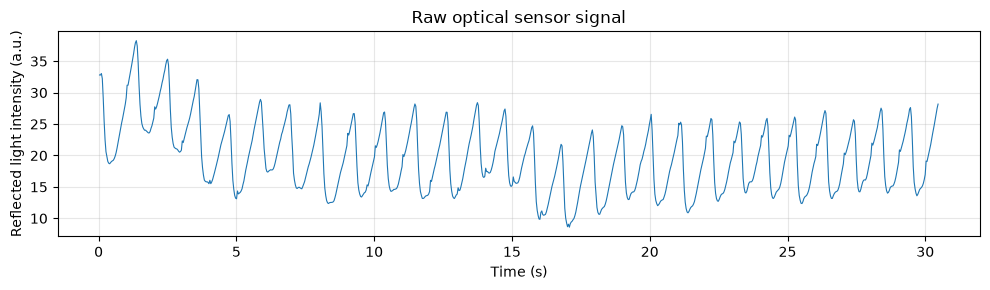

In [2]:
fig, ax = plt.subplots(figsize=(10, 3))                  # wide figure suits a time series
ax.plot(t, x, linewidth=0.8)                             # raw signal against time
ax.set_xlabel("Time (s)")                                # x-axis label with units
ax.set_ylabel("Reflected light intensity (a.u.)")        # a.u. = arbitrary units
ax.set_title("Raw optical sensor signal")                # figure title
ax.grid(alpha=0.3)                                       # light grid makes values easier to read
fig.tight_layout()                                       # stop labels being cut off
fig.savefig("figures/A1_raw_signal.png", dpi=200)        # save a high-resolution copy for the report
plt.show()                                               # display the figure in the notebook

## A.3 Pre-processing: detrending and band-pass filtering
A linear trend is removed to correct baseline drift. A zero-phase Butterworth band-pass filter (0.7–3 Hz, i.e. 42–180 bpm) then keeps only frequencies in the physiological heart-rate range, removing respiration and high-frequency noise.

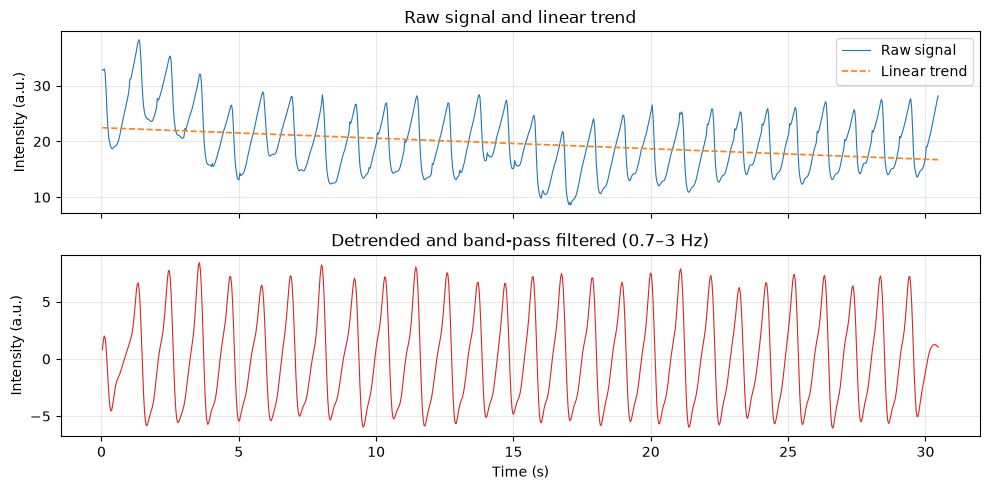

In [3]:
def bandpass(signal, fs, band=HR_BAND, order=3):
    """Zero-phase Butterworth band-pass filter keeping the heart-rate band."""
    b, a = butter(order, band, btype="band", fs=fs)  # design the filter coefficients
    return filtfilt(b, a, signal)                    # filter forwards and backwards: no time delay                             


x_detrended = detrend(x)                     # remove the linear baseline drift
trend = x - x_detrended                      # the straight line that was removed (for plotting)
x_filtered = bandpass(x_detrended, fs)       # keep only 0.7–3 Hz (42–180 bpm)

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)        # two panels sharing the time axis

axes[0].plot(t, x, linewidth=0.8, label="Raw signal")                # top: raw data
axes[0].plot(t, trend, "--", linewidth=1.2, label="Linear trend")    # top: the drift being removed
axes[0].set_ylabel("Intensity (a.u.)")
axes[0].set_title("Raw signal and linear trend")
axes[0].legend(loc="upper right")
axes[0].grid(alpha=0.3)

axes[1].plot(t, x_filtered, color="tab:red", linewidth=0.8)          # bottom: cleaned signal
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Intensity (a.u.)")
axes[1].set_title("Detrended and band-pass filtered (0.7–3 Hz)")
axes[1].grid(alpha=0.3)

fig.tight_layout()
fig.savefig("figures/A2_filtered_signal.png", dpi=200)               # save for the report
plt.show()

## A.4 Heart rate from the frequency spectrum (Task 1.2)
The filtered signal is transformed with the Fast Fourier Transform (FFT). A periodic heartbeat appears as a peak in the amplitude spectrum; the frequency of the largest peak inside the 0.7–3 Hz band is the dominant cardiac frequency $f_{HR}$, and the heart rate is $HR = 60 \times f_{HR}$ bpm.
The frequency resolution is $\Delta f = f_s / N$, so the bpm estimate is only precise to about $\pm 60\,\Delta f / 2$.


FFT heart rate = 55.1 bpm
Frequency resolution = 0.033 Hz (±1.0 bpm)


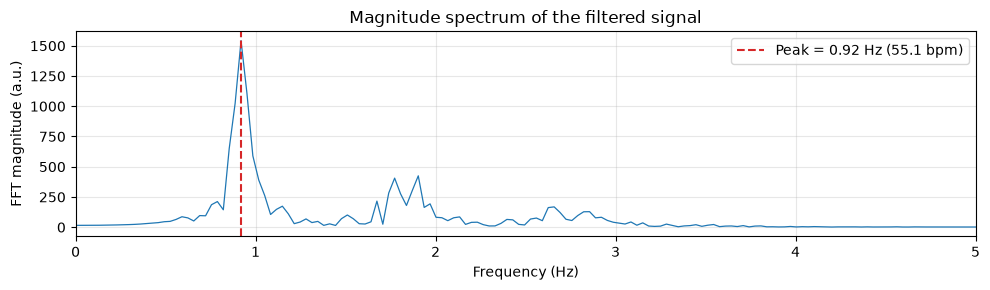

In [4]:
def estimate_hr_fft(signal, fs, band=HR_BAND):
    """Estimate heart rate (bpm) from the largest spectral peak inside the heart-rate band."""
    magnitude = np.abs(np.fft.rfft(signal))                    # magnitude spectrum (positive frequencies only)
    freqs = np.fft.rfftfreq(len(signal), d=1 / fs)             # frequency of each FFT bin (Hz)
    in_band = (freqs >= band[0]) & (freqs <= band[1])          # mask for the heart-rate band
    f_peak = freqs[in_band][np.argmax(magnitude[in_band])]     # dominant cardiac frequency
    return f_peak * 60, f_peak, freqs, magnitude               # bpm, Hz, and spectrum for plotting


hr_fft, f_peak, freqs, magnitude = estimate_hr_fft(x_filtered, fs)               # run on the optical signal
print(f"FFT heart rate = {hr_fft:.1f} bpm")
print(f"Frequency resolution = {fs / len(x_filtered):.3f} Hz "
      f"(±{30 * fs / len(x_filtered):.1f} bpm)")                                 # half a bin, in bpm

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(freqs, magnitude, linewidth=0.9)             # rfft already returns only non-negative frequencies
ax.axvline(f_peak, color="tab:red", linestyle="--",
           label=f"Peak = {f_peak:.2f} Hz ({hr_fft:.1f} bpm)")
ax.set_xlim(0, 5)                                    # the heart-rate peak is well below 5 Hz
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("FFT magnitude (a.u.)")
ax.set_title("Magnitude spectrum of the filtered signal")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("figures/A3_fft_spectrum.png", dpi=200)
plt.show()


## A.5 Validation with peak detection
As an independent check, individual heartbeats are found in the time domain with `find_peaks`. Peaks must be at least int(fs × 60 / 180) = 9 samples (0.30 s) apart, so no faster than about 180 bpm and higher than one standard deviation of the signal, so small bumps at the start and end are ignored. The mean time between beats gives a second heart-rate estimate, which should agree with the FFT result.


27 beats detected, heart rate = 55.5 bpm
Difference from FFT = 0.4 bpm


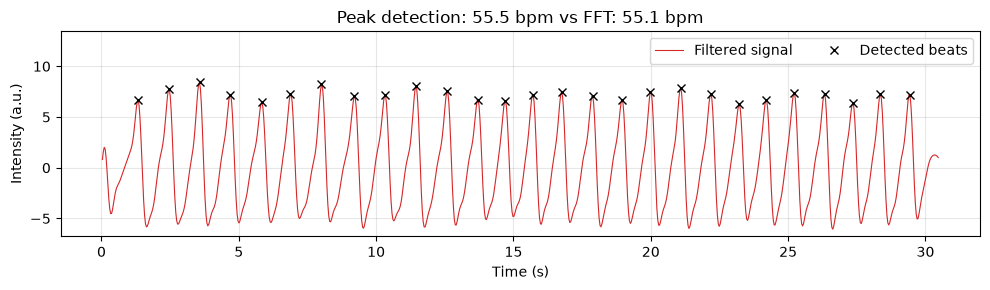

In [5]:
def estimate_hr_peaks(signal, t, fs, max_bpm=180):
    """Estimate heart rate (bpm) from the mean interval between detected beats."""
    min_gap = int(fs * 60 / max_bpm)                            # minimum samples between beats
    peaks, _ = find_peaks(signal, distance=min_gap,
                          height=np.std(signal))                # ignore small bumps at the edges
    ibi = np.diff(t[peaks])                                     # inter-beat intervals (s)
    return 60 / np.mean(ibi), peaks, ibi                        # bpm, beat indices, intervals


hr_peaks, peaks, ibi = estimate_hr_peaks(x_filtered, t, fs)                      # run on the optical signal
print(f"{len(peaks)} beats detected, heart rate = {hr_peaks:.1f} bpm")
print(f"Difference from FFT = {abs(hr_peaks - hr_fft):.1f} bpm")

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(t, x_filtered, color="tab:red", linewidth=0.8, label="Filtered signal")
ax.plot(t[peaks], x_filtered[peaks], "kx", markersize=6, label="Detected beats")
ax.set_ylim(top=1.6 * x_filtered.max())  # leave room so the legend does not cover any beats
ax.set_xlabel("Time (s)")
ax.set_ylabel("Intensity (a.u.)")
ax.set_title(f"Peak detection: {hr_peaks:.1f} bpm vs FFT: {hr_fft:.1f} bpm")
ax.legend(loc="upper right", ncol=2)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("figures/A4_peak_detection.png", dpi=200)
plt.show()


## A.6 Summary of Part A
Both methods give consistent heart-rate estimates. The results and the filtered signal are saved to `data/` so they can be reused and submitted.

In [6]:
results_A = pd.DataFrame({
    "method": ["FFT", "Peak detection"],
    "heart_rate_bpm": [round(hr_fft, 1), round(hr_peaks, 1)],
})                                                                     # one row per method
print(results_A.to_string(index=False))                               # show the table without row numbers

beat_hr = 60 / ibi                                                     # heart rate of each individual beat
print(f"Beat-to-beat heart rate: {beat_hr.mean():.1f} ± {beat_hr.std():.1f} bpm (mean ± SD)")

results_A.to_csv("data/partA_results.csv", index=False)                # save the results table
pd.DataFrame({"time_s": t, "filtered_signal": x_filtered}).to_csv(
    "data/partA_filtered_signal.csv", index=False)                    # save the processed signal

        method  heart_rate_bpm
           FFT            55.1
Peak detection            55.5
Beat-to-beat heart rate: 55.7 ± 3.1 bpm (mean ± SD)


# Part B – Video Heart Rate

## B.1 Load the video and extract the mean grayscale per frame
A fingertip pressed on the phone camera (with the flash on) is lit from behind. Each heartbeat changes how much blood is in the fingertip, which slightly changes how much light reaches the sensor. Averaging every pixel of a frame to a single number turns the video into a 1-D time series, just like the optical sensor signal in Part A.

The sampling rate is the video frame rate, and the time of frame *i* is *i / fps*.

Part B reuses the imports, `HR_BAND` and the `bandpass` function defined in Part A, so the notebook should be run from the top (Restart & Run All).
Videos must provide at least 10 seconds of decodable frames and a finite frame rate above 6 Hz. Empty, short or flat recordings raise a clear error.


In [7]:
import cv2                              # OpenCV: reads the video frame by frame

VIDEO_PATH = "data/video_of_finger.MOV" # video is not in git (118 MB); download it from Moodle


def load_video_signal(path):
    """Return time (s), mean grayscale value per frame, and frame rate (fps)."""
    cap = cv2.VideoCapture(path)                              # open the video file
    try:
        if not cap.isOpened():
            raise FileNotFoundError(f"Cannot open {path}")        # clear error if the file is missing
        fps = cap.get(cv2.CAP_PROP_FPS)                           # frames per second = sampling rate
        if not np.isfinite(fps) or fps <= 2 * HR_BAND[1]:         # Nyquist: must sample above 6 Hz
            raise ValueError("Video frame rate must be finite and above 6 Hz.")
        means = []
        while True:
            ok, frame = cap.read()                                # read the next frame (BGR image)
            if not ok:                                            # no more frames
                break
            gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)        # colour -> grayscale
            means.append(gray.mean())                             # average over all pixels in the frame
    finally:
        cap.release()                                             # release even if decoding or validation fails

    # Ten seconds gives at least seven cycles at the lower band edge (0.7 Hz).
    if len(means) < int(np.ceil(10 * fps)):
        raise ValueError("Video must contain at least 10 seconds of decodable frames.")
    v = np.array(means)
    if np.std(v) < 1e-8:                                          # numerical tolerance, not a physiological threshold
        raise ValueError("Cannot estimate heart rate: video signal has no usable variation.")
    t = np.arange(len(v)) / fps                                   # time of each frame in seconds
    return t, v, fps


t_v, v, fs_v = load_video_signal(VIDEO_PATH)
print(f"{len(t_v)} frames, fps = {fs_v:.2f} Hz, duration = {t_v[-1]:.1f} s")  # quick sanity check

1852 frames, fps = 29.98 Hz, duration = 61.7 s


## B.2 Plot the mean grayscale signal (Task 1)
The mean grayscale value of each frame is plotted against time in seconds.

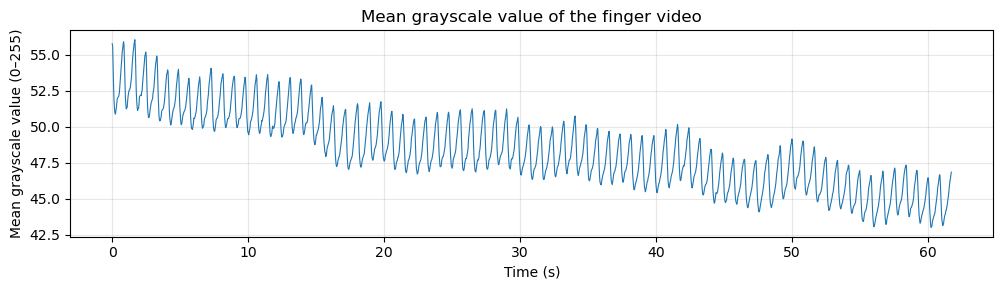

In [8]:
fig, ax = plt.subplots(figsize=(10, 3))                  # wide figure suits a time series
ax.plot(t_v, v, linewidth=0.8)                           # mean grayscale per frame
ax.set_xlabel("Time (s)")                                # x-axis label with units
ax.set_ylabel("Mean grayscale value (0–255)")            # 8-bit grayscale range
ax.set_title("Mean grayscale value of the finger video")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("figures/B1_raw_video_signal.png", dpi=200)  # high-resolution copy for the report
plt.show()

pd.DataFrame({"time_s": t_v, "mean_gray": v}).to_csv(
    "data/partB_mean_gray.csv", index=False)             # save so filtering/FFT can reuse it without re-reading the video

## B.3 Pre-processing: detrending and band-pass filtering
The raw video signal drifts downwards over the minute (e.g. the finger pressure or the camera's auto-exposure changes). This slow drift is far larger than the pulse and would dominate the low-frequency end of the spectrum, so it is removed first. The same `bandpass` function and 0.7–3 Hz heart-rate band as in Part A are then applied. The video frame rate (about 30 Hz) is well above the 6 Hz needed to sample frequencies up to 3 Hz (Nyquist).

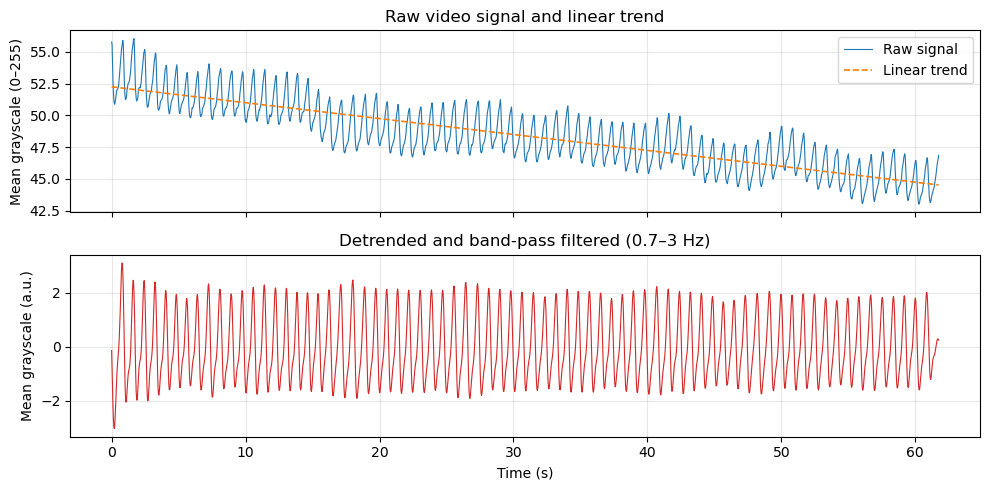

In [9]:
v_detrended = detrend(v)                     # remove the linear baseline drift
trend_v = v - v_detrended                    # the straight line that was removed (for plotting)
v_filtered = bandpass(v_detrended, fs_v)     # keep only 0.7–3 Hz (42–180 bpm)

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)        # two panels sharing the time axis

axes[0].plot(t_v, v, linewidth=0.8, label="Raw signal")              # top: raw data
axes[0].plot(t_v, trend_v, "--", linewidth=1.2, label="Linear trend")  # top: the drift being removed
axes[0].set_ylabel("Mean grayscale (0–255)")
axes[0].set_title("Raw video signal and linear trend")
axes[0].legend(loc="upper right")
axes[0].grid(alpha=0.3)

axes[1].plot(t_v, v_filtered, color="tab:red", linewidth=0.8)        # bottom: cleaned signal
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Mean grayscale (a.u.)")
axes[1].set_title("Detrended and band-pass filtered (0.7–3 Hz)")
axes[1].grid(alpha=0.3)

fig.tight_layout()
fig.savefig("figures/B2_filtered_video_signal.png", dpi=200)         # save for the report
plt.show()